# Регрессия

# Автор: Олег Булыгин

<div style="background-color: #f5f5f5; border-left: 5px solid #3498db; padding: 10px; margin: 10px 0;">

## Обо мне

🐍 **Эксперт по Python и Data Science**. В 2020 году ушёл из найма, сейчас реализую собственные проекты, занимаюсь IT-образованием и консультированием.

👨‍💻 **Опыт в образовании**. В IT-образовании с 2016 года. За это время провел более 3000 лекций и вебинаров, обучил тысячи студентов, многие из которых сейчас работают в ведущих IT-компаниях. Создаю авторские курсы, консультирую крупные компании по вопросам Data Science и участвую в разработке образовательных программ для университетов и онлайн-школ.

🎯 Стремлюсь сделать обучение качественным и честным для всех, кто хочет развиваться в IT-сфере.

📱 Делюсь полезными материалами о Python:
- [Telegram](https://t.me/pythontalk)
- [Дзен](https://dzen.ru/pythontalk)
</div>


Задача регрессии (regression) — это задача, в которой мы пытаемся предсказать вещественное число на основе признаков в наборе данных. То есть задача сводится к предсказанию целевого признака, который является числовым.

Задачи регрессии относятся к группе задач "обучения с учителем" (supervised learning) — то есть для реализации алгоритма нам необходимы размеченные данные с признаками и целевым значением.

К примеру, с помощью регрессии мы предсказываем цену квартиры, рейтинг вина при слепом тестировании, длительность поездки в такси в зависимости от времени суток, желаемую заработную плату соискателя.



## Линейная регрессия

Линейная регрессия (Linear Regression) — одна из простейших моделей для решения задачи регрессии. Главная гипотеза состоит в том, что рассматриваемая зависимость является линейной.




### Пример регрессии

Поработаем с данными (анонимизированными) компании, которая продает одежду онлайн, но также предоставляет консультации стилистов в своих магазинах. Клиенты приходят в магазин, проходят консультации со стилистом, а затем могут пойти домой и заказать через мобильное приложение или веб-сайт ту одежду, которую они хотят.


Значимые столбцы:

* Avg. Session Length: среднее время консультации стилиста оффлайн
* Time on App: среднее время клиента в приложении
* Time on Website: средняя время клиента на сайте
* Length of Membership: сколько лет клиент пользуется услугами компании.

Для клиентов, которые уже пользуются услугами компании, модель может помочь в прогнозировании их будущих расходов. Также модель может помочь понять, какие каналы имеют большее влияние на целевую переменную.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/obulygin/content/main/ecommers_customers/ecommerce.csv')
df

In [ ]:
df = df.drop(columns=['Email', 'Address', 'Avatar'], axis=1)
df

Модель линейной регрессии (как и многие другие) требует, чтобы в подаваемых ей на вход данных не было пропущенных значений. Поэтому если в ваших данных окажутся пропуски, нужно их заранее предобработать.


In [ ]:
df.describe()

In [ ]:
df.info()

## Изучим взаимосвязи

Построим pairplot, чтобы выдвинуть гипотезы о взаимосвязи признаков.

In [ ]:
sns.pairplot(df)
plt.suptitle('Матрица диаграмм рассеяния и гистограмм', y=1.02)
plt.show()

Также построим матрицу корреляций

In [ ]:
# Рассчитываем матрицу корреляций
correlation_matrix = df.corr()

# Строим тепловую карту
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Тепловая карта корреляций признаков')
plt.show()

## Построение модели

Подготовим выборки для обучения модели

In [ ]:
X = df[['Avg. Session Length', 'Time on App',
       'Time on Website', 'Length of Membership']]

y = df['Yearly Amount Spent']

Разделим выборку на тестовую и тренировочную.

На тренировочном наборе данных мы будем обучать модель. **Оценка качества работы модели на тренировочной выборке не показательна**. Ведь наш алгоритм всегда мог подстроить свои параметры так, чтобы результат именно на этой тренировочной выборке будет хорошим, однако ни к каким другим данным его применить будет нельзя.

Логика такая же, как у учителей в школе: если дать ученику домашнюю работу, то он может подсмотреть ответы в конце учебника и просто их запомнить, не разобравшись в теме. Поэтому на контрольной работе необходимо дать задачи, которые будут отличаться от выданных ранее в качестве домашней работы. В данном случае, тренировочной выборкой выступает домашнее задание, его цель - натренировать ученика, научить его решать некоторый тип задач. А тестовая выборка - это контрольная работа. Домашнюю работу хорошо решить могут и плохой, и хороший ученики, а вот контрольную хорошо решит только хороший.


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lm = LinearRegression()

In [ ]:
lm.fit(X_train, y_train)

LinearRegression()

In [ ]:
predictions = lm.predict(X_test)
predictions

array([403.36087526, 542.49652255, 426.79061944, 501.98000522,
       409.90016607, 569.95203575, 531.68712688, 506.10842617,
       408.47031037, 473.71493101, 441.30201774, 425.05268133,
       424.93655583, 527.27340348, 431.24084639, 423.76635768,
       575.73837263, 484.73375076, 458.15131382, 481.73089746,
       502.04156769, 513.39008852, 507.55579577, 646.54871994,
       449.98886069, 496.07689142, 556.2403381 , 554.77842999,
       399.41536028, 325.54121912, 532.65563818, 477.96272707,
       500.87585571, 305.69578623, 505.5581936 , 483.59198597,
       518.72294437, 437.96539568, 456.5172541 , 470.84325957,
       494.20975196, 445.1840947 , 508.62394573, 500.91793768,
       488.73418105, 535.19202701, 595.04122136, 513.81284729,
       280.44329112, 433.04560196, 421.42401729, 481.13163584,
       584.63530063, 608.71467973, 564.01947373, 494.49273084,
       394.32484472, 456.44102533, 572.84643521, 499.46263062,
       512.73482583, 391.89419968, 479.80345348, 481.34

## Интерпретация коэффициентов

Обученная модель нашла оптимальные коэффициенты для каждого признака (lm.coef_) и свободный член (lm.intercept_), которые минимизируют ошибку предсказания на обучающих данных. Эти коэффициенты формируют уравнение прямой (или гиперплоскости в нашем случае, т.к. признаков несколько):



In [ ]:
lm.coef_

array([25.69083176, 38.68815596,  0.45279908, 61.71050259])

In [ ]:
lm.intercept_

np.float64(-1050.707388040164)

`y = 25.7 * Avg_sess_length + 38.7 * time_on_app + 0.45 * time_on_website + 61.71 * length_of_membership - 1051`

Для удобства составим DataFrame из коэффициентов обученной модели.

In [ ]:
lr_df = pd.DataFrame({'Признаки': X_train.columns, 'Коэффициенты': lm.coef_})

intercept_df = pd.DataFrame({'Признаки': ['Intercept'], 'Коэффициенты': lm.intercept_})
coef_df = pd.concat([lr_df, intercept_df], ignore_index=True)
coef_df

,Признаки,Коэффициенты
0,Avg. Session Length,25.690832
1,Time on App,38.688156
2,Time on Website,0.452799
3,Length of Membership,61.710503
4,Intercept,-1050.707388


Как интерпретировать эти коэффициенты?
Возьмем, к примеру, коэффициент для `Time on App`. Он равен примерно 38.7.

*   **Буквальная интерпретация:** Удерживая все остальные признаки неизменными, увеличение `Time on App` на одну единицу (в нашем случае, одну минуту) связано с увеличением `Yearly Amount Spent` в среднем на 38.7 долларов.
*   Аналогично для `Length of Membership`: Удерживая все остальные признаки неизменными, увеличение `Length of Membership` на одну единицу (один год) связано с увеличением `Yearly Amount Spent` в среднем на 61.7 долларов.

Cвободный член (Intercept) имитирует влияние внешних факторов и носит смысл «поправки» модели относительно медианной стоимости.



Можем ли мы сказать, что `Length of Membership` – самый "важный" признак, потому что у него самый большой коэффициент? А `Time on Website` – самый незначительный? **Не совсем.**


Может показаться, что, если величина по модулю коэффицента для определенного признака больше, то признак играет бОльшую роль в предсказании. Однако это не обязательно так.

Величина коэффициента уравнения регрессии по модулю не всегда говорит о большей важности признака для модели. Это потому, что коэффициенты зависят от единиц измерения признаков и масштаба данных. Если признаки имеют разный масштаб, то их коэффициенты не могут быть напрямую сравнены. Если признаки имеют одинаковые единицы измерения, но разный масштаб, то их коэффициенты также будут разными. В таких случаях, для сравнения важности признаков стоит масштабировать данные.

Пример, когда при большем коэффициенте по модулю признак может быть менее значим для модели, чем другой:

Предположим, что мы хотим построить линейную регрессию для предсказания цены квартиры в зависимости от площади и количества комнат. Допустим, что площадь измеряется в квадратных метрах, а количество комнат - в штуках. Допустим, что у нас есть следующие данные:

| Площадь (м2) | Количество комнат | Цена (млн. руб.) |
|--------------|-------------------|-------------------|
| 40           | 1                 | 5                 |
| 60           | 2                 | 8                 |
| 80           | 3                 | 11                |
| 100          | 4                 | 14                |

Если мы построим линейную регрессию по этим данным, то мы получим следующее уравнение:

$$y = 0.1x_1 + 1x_2$$

где $y$ - цена квартиры, $x_1$ - площадь, $x_2$ - количество комнат.

По модулю, коэффициент при количестве комнат больше, чем при площади. Однако, это не значит, что количество комнат важнее, чем площадь для модели. Это связано с тем, что площадь и количество комнат имеют разные единицы измерения и масштаб. Если мы измерим площадь в квадратных сантиметрах, то уравнение регрессии изменится:

$$y = 0.0001x_1 + 1x_2$$

где $x_1$ - площадь в квадратных сантиметрах.

В этом случае, коэффициент при площади стал еще меньше по модулю, но это не означает, что площадь должна стать менее значимой для модели.


## Интерпретация коэффициентов

Обученная модель нашла оптимальные коэффициенты для каждого признака (lm.coef_) и свободный член (lm.intercept_), которые минимизируют ошибку предсказания на обучающих данных. Эти коэффициенты формируют уравнение прямой (или гиперплоскости в нашем случае, т.к. признаков несколько):



In [ ]:
lm.coef_

array([25.69083176, 38.68815596,  0.45279908, 61.71050259])

In [ ]:
lm.intercept_

np.float64(-1050.707388040164)

`y = 25.7 * Avg_sess_length + 38.7 * time_on_app + 0.45 * time_on_website + 61.71 * length_of_membership - 1051`

Для удобства составим DataFrame из коэффициентов обученной модели.

In [ ]:
lr_df = pd.DataFrame({'Признаки': X_train.columns, 'Коэффициенты': lm.coef_})

intercept_df = pd.DataFrame({'Признаки': ['Intercept'], 'Коэффициенты': lm.intercept_})
coef_df = pd.concat([lr_df, intercept_df], ignore_index=True)
coef_df

,Признаки,Коэффициенты
0,Avg. Session Length,25.690832
1,Time on App,38.688156
2,Time on Website,0.452799
3,Length of Membership,61.710503
4,Intercept,-1050.707388


Как интерпретировать эти коэффициенты?
Возьмем, к примеру, коэффициент для `Time on App`. Он равен примерно 38.7.

*   **Буквальная интерпретация:** Удерживая все остальные признаки неизменными, увеличение `Time on App` на одну единицу (в нашем случае, одну минуту) связано с увеличением `Yearly Amount Spent` в среднем на 38.7 долларов.
*   Аналогично для `Length of Membership`: Удерживая все остальные признаки неизменными, увеличение `Length of Membership` на одну единицу (один год) связано с увеличением `Yearly Amount Spent` в среднем на 61.7 долларов.

Cвободный член (Intercept) имитирует влияние внешних факторов и носит смысл «поправки» модели относительно медианной стоимости.



Можем ли мы сказать, что `Length of Membership` – самый "важный" признак, потому что у него самый большой коэффициент? А `Time on Website` – самый незначительный? **Не совсем.**


Может показаться, что, если величина по модулю коэффицента для определенного признака больше, то признак играет бОльшую роль в предсказании. Однако это не обязательно так.

Величина коэффициента уравнения регрессии по модулю не всегда говорит о большей важности признака для модели. Это потому, что коэффициенты зависят от единиц измерения признаков и масштаба данных. Если признаки имеют разный масштаб, то их коэффициенты не могут быть напрямую сравнены. Если признаки имеют одинаковые единицы измерения, но разный масштаб, то их коэффициенты также будут разными. В таких случаях, для сравнения важности признаков стоит масштабировать данные.

Пример, когда при большем коэффициенте по модулю признак может быть менее значим для модели, чем другой:

Предположим, что мы хотим построить линейную регрессию для предсказания цены квартиры в зависимости от площади и количества комнат. Допустим, что площадь измеряется в квадратных метрах, а количество комнат - в штуках. Допустим, что у нас есть следующие данные:

| Площадь (м2) | Количество комнат | Цена (млн. руб.) |
|--------------|-------------------|-------------------|
| 40           | 1                 | 5                 |
| 60           | 2                 | 8                 |
| 80           | 3                 | 11                |
| 100          | 4                 | 14                |

Если мы построим линейную регрессию по этим данным, то мы получим следующее уравнение:

$$y = 0.1x_1 + 1x_2$$

где $y$ - цена квартиры, $x_1$ - площадь, $x_2$ - количество комнат.

По модулю, коэффициент при количестве комнат больше, чем при площади. Однако, это не значит, что количество комнат важнее, чем площадь для модели. Это связано с тем, что площадь и количество комнат имеют разные единицы измерения и масштаб. Если мы измерим площадь в квадратных сантиметрах, то уравнение регрессии изменится:

$$y = 0.0001x_1 + 1x_2$$

где $x_1$ - площадь в квадратных сантиметрах.

В этом случае, коэффициент при площади стал еще меньше по модулю, но это не означает, что площадь должна стать менее значимой для модели.


## Масштабирование данных

Как мы выяснили, сравнивать "сырые" коэффициенты линейной регрессии для оценки важности признаков некорректно, если признаки имеют разный масштаб. Масштабирование решает эту проблему.

**Основная цель масштабирования в данном контексте:** Привести все признаки к единому масштабу, чтобы их коэффициенты в модели стали напрямую сравнимы. Коэффициент при масштабированном признаке покажет, на сколько изменится целевая переменная (в своих исходных единицах), если сам признак изменится на одну единицу *своего стандартного отклонения*.

Для классической линейной регрессии, решаемой аналитически, масштабирование не влияет на качество предсказаний (R² будет тем же), но **критически важно для корректной интерпретации относительной важности признаков**.


Есть много инструментов масштабирования, часто используется стандартизация или нормализация данных.

**Стандартизация** данных приводит все признаки к примерно одному масштабу, с нулевым средним значением и единичной дисперсией (стандартным отклонением, равным 1). Это достигается путем вычитания среднего значения признака из каждого значения и деления на стандартное отклонение этого признака.


**Мин-макс нормализация** преобразование масштабирует данные в указанном диапазоне (обычно от 0 до 1). Это достигается путем деления каждого значения признака на максимальное значение этого признака.

Если диапазоны значений сильно различаются, стандартизация может быть предпочтительнее. А нормализация может быть полезна, когда мы работаем с данными, которые имеют аномальные значения или выбросы, так как она уменьшает влияние этих значений (если мы хотим его уменьшить).

Некоторые алгоритмы лучше работают со стандартизированными данными, а другие - с нормализованными. Можно пробовать варианты :)




Реализуем для примера стандартизацию, она является одним из самых используемых инструментов и часто применяется в задачах регрессии и классификации.


$$\hat{x} = \frac{x - μ}{σ}$$

Где $μ$ - математическое ожидание, которое обычно заменяется просто выборочной оценкой (среднему значению $x$ по выборке), а $σ$ - стандартное отклонение.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Подбираем параметры стандартизатора (вычисляем среднее и СКО)
scaler.fit(X_train)

# Производим стандартизацию тренировочной выборки
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled


array([[-1.10854092,  1.04846314,  0.60725474, -0.90827256],
       [-0.83963017,  0.17397435, -0.03355509, -0.65085616],
       [-2.01405298, -0.85023089,  1.67222401, -0.47569707],
       ...,
       [-1.24478547, -1.16512639, -2.05534971, -0.43650991],
       [-0.79495159,  2.10322037,  0.03480347,  0.18599669],
       [-0.62835981, -0.5992723 ,  0.58221759, -0.96883841]])

ВАЖНО: Мы обучаем scaler (находим μ и σ) ТОЛЬКО на обучающей выборке (X_train).
Если бы мы обучили его на всех данных (X), то информация из тестовой выборки
"протекла" бы в процесс обучения, и оценка модели на тесте была бы нечестной.

Результат - это NumPy массивы, где каждый признак имеет среднее ~0 и ст.откл. ~1


In [ ]:
# Преобразуем в DataFrame для наглядности с колонками
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_train_scaled_df

,Avg. Session Length,Time on App,Time on Website,Length of Membership
0,-1.108541,1.048463,0.607255,-0.908273
1,-0.839630,0.173974,-0.033555,-0.650856
2,-2.014053,-0.850231,1.672224,-0.475697
3,-0.395576,-0.086742,-0.347530,0.524049
4,-0.214006,1.148976,-1.048679,-1.719045
...,...,...,...,...
370,-0.763002,0.147412,-0.821668,0.205409
371,0.960709,0.918493,1.639171,-0.291952
372,-1.244785,-1.165126,-2.055350,-0.436510
373,-0.794952,2.103220,0.034803,0.185997


In [ ]:
X_train_scaled_df.describe().loc[['mean', 'std']]


,Avg. Session Length,Time on App,Time on Website,Length of Membership
mean,-9.805490e-16,5.305386e-16,-2.529532e-15,-2.498742e-16
std,1.001336e+00,1.001336e+00,1.001336e+00,1.001336e+00


In [ ]:
lm_scaled = LinearRegression()
lm_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = lm_scaled.predict(X_test_scaled)
y_pred_scaled

array([403.36087526, 542.49652255, 426.79061944, 501.98000522,
       409.90016607, 569.95203575, 531.68712688, 506.10842617,
       408.47031037, 473.71493101, 441.30201774, 425.05268133,
       424.93655583, 527.27340348, 431.24084639, 423.76635768,
       575.73837263, 484.73375076, 458.15131382, 481.73089746,
       502.04156769, 513.39008852, 507.55579577, 646.54871994,
       449.98886069, 496.07689142, 556.2403381 , 554.77842999,
       399.41536028, 325.54121912, 532.65563818, 477.96272707,
       500.87585571, 305.69578623, 505.5581936 , 483.59198597,
       518.72294437, 437.96539568, 456.5172541 , 470.84325957,
       494.20975196, 445.1840947 , 508.62394573, 500.91793768,
       488.73418105, 535.19202701, 595.04122136, 513.81284729,
       280.44329112, 433.04560196, 421.42401729, 481.13163584,
       584.63530063, 608.71467973, 564.01947373, 494.49273084,
       394.32484472, 456.44102533, 572.84643521, 499.46263062,
       512.73482583, 391.89419968, 479.80345348, 481.34

In [ ]:
lr_df = pd.DataFrame({'Признаки': X_train.columns, 'Коэффициенты': lm .coef_})

intercept_df = pd.DataFrame({'Признаки': ['Intercept'], 'Коэффициенты': lm .intercept_})
coef_df = pd.concat([lr_df, intercept_df], ignore_index=True)
coef_df

,Признаки,Коэффициенты
0,Avg. Session Length,25.690832
1,Time on App,38.688156
2,Time on Website,0.452799
3,Length of Membership,61.710503
4,Intercept,-1050.707388


In [ ]:
lr_scaled_df = pd.DataFrame({'Признаки': X_train.columns, 'Коэффициенты': lm_scaled.coef_})

intercept_df_scaled = pd.DataFrame({'Признаки': ['Intercept'], 'Коэффициенты': lm_scaled.intercept_})
coef_df_scaled = pd.concat([lr_scaled_df, intercept_df_scaled], ignore_index=True)
coef_df_scaled

,Признаки,Коэффициенты
0,Avg. Session Length,25.557009
1,Time on App,38.423304
2,Time on Website,0.460489
3,Length of Membership,62.793522
4,Intercept,501.585694


Масштабирование позволило нам сделать **обоснованный вывод об относительной силе влияния** каждого признака на целевую переменную, чего мы не могли сделать с "сырыми" коэффициентами.

Мы увидели, что масштабированный коэффициент для `Time on Website` очень близок к нулю. Это говорит о том, что данный признак вносит минимальный вклад в предсказание `Yearly Amount Spent` в нашей модели. Давайте проверим, что произойдет с моделью, если мы его удалим.


In [ ]:
X_train_small = X_train[['Avg. Session Length', 'Time on App', 'Length of Membership']]
X_test_small = X_test[['Avg. Session Length', 'Time on App', 'Length of Membership']]

scaler = StandardScaler()
scaler.fit(X_train_small)
X_train_small_scaled = scaler.transform(X_train_small)
X_test_small_scaled = scaler.transform(X_test_small)

lm_small = LinearRegression()
lm_small.fit(X_train_small_scaled, y_train)
y_pred_small = lm_small.predict(X_test_small_scaled)
y_pred_small

array([402.37484408, 542.49221712, 426.23050397, 501.91540904,
       409.36735372, 569.36618691, 532.24974957, 505.83124281,
       408.14572061, 473.37876664, 441.22262949, 424.63905882,
       425.60118109, 527.59620306, 430.72657622, 424.1237315 ,
       576.03919509, 485.12606416, 458.04997706, 481.69938453,
       501.73404389, 513.47161445, 507.34650695, 646.21908059,
       450.15524134, 496.82789117, 555.58567544, 555.20086086,
       399.21753802, 325.70359488, 532.93442473, 477.3757435 ,
       500.9460797 , 305.75843758, 505.47114595, 484.10754319,
       519.51101091, 438.30778414, 456.15611874, 470.6428516 ,
       494.56063656, 444.94602641, 508.92063786, 500.8856393 ,
       487.92151051, 535.65361414, 593.8879854 , 513.75792445,
       279.61827505, 432.30797067, 420.92086487, 480.84907891,
       583.72780946, 607.91711055, 564.32607196, 495.27568246,
       394.37975314, 455.98356649, 573.51087382, 498.85403384,
       512.34881154, 391.96886581, 479.46256109, 481.27

In [ ]:
lr_scaled_df = pd.DataFrame({'Признаки': X_train_small.columns, 'Коэффициенты': lm_small.coef_})

intercept_df_scaled = pd.DataFrame({'Признаки': ['Intercept'], 'Коэффициенты': lm_scaled.intercept_})
coef_df_scaled = pd.concat([lr_scaled_df, intercept_df_scaled], ignore_index=True)
coef_df_scaled

,Признаки,Коэффициенты
0,Avg. Session Length,25.564756
1,Time on App,38.452396
2,Length of Membership,62.773855
3,Intercept,501.585694


## Оценка модели

In [ ]:
from sklearn.metrics import r2_score

print(f'R2: {r2_score(y_test, y_pred_scaled)}')
print(f'R2: {r2_score(y_test, y_pred_small)}')

R2: 0.9806693454258992
R2: 0.980655952626855


Помимо метрик, полезно визуально оценить качество предсказаний. Построим диаграмму рассеяния, где по оси X отложим реальные значения (`y_test`), а по оси Y – предсказанные значения (`y_pred_scaled` от полной модели).


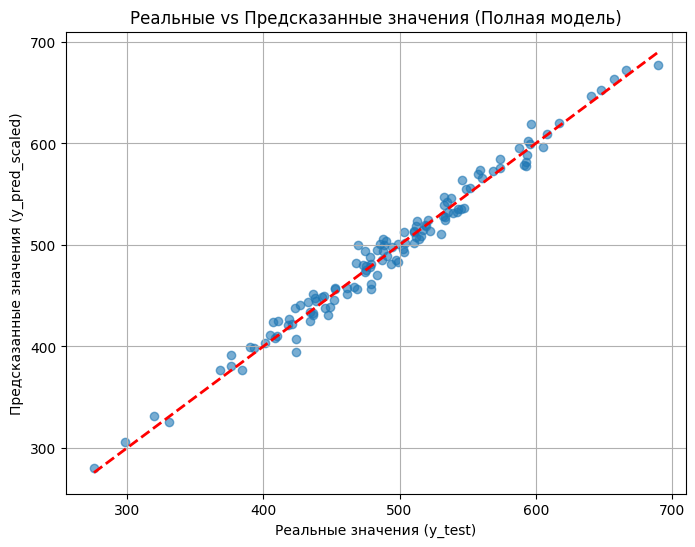

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_scaled, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2) # Диагональная линия y=x
plt.xlabel("Реальные значения (y_test)")
plt.ylabel("Предсказанные значения (y_pred_scaled)")
plt.title("Реальные vs Предсказанные значения (Полная модель)")
plt.grid(True)
plt.show()

Точки на графике достаточно плотно группируются вокруг красной пунктирной линии (линии `y=x`). Это означает, что предсказанные значения в целом близки к реальным. Если бы точки были сильно разбросаны или образовывали какой-то другой паттерн, это указывало бы на проблемы в модели.


Остатки – это разница между реальными и предсказанными значениями (`y_test - y_pred`). Анализ их распределения помогает проверить некоторые допущения линейной регрессии. В идеале остатки должны быть распределены нормально с центром в нуле и иметь постоянную дисперсию (гомоскедастичность).


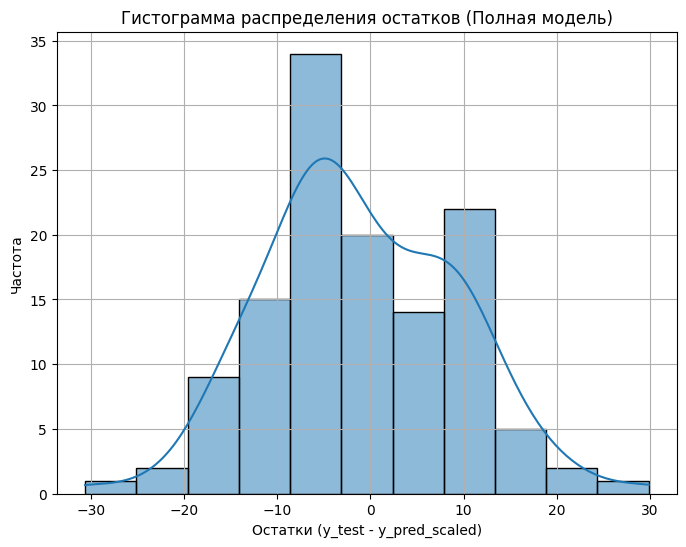

In [ ]:
residuals = y_test - y_pred_scaled

# Строим гистограмму остатков
plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True)
plt.xlabel("Остатки (y_test - y_pred_scaled)")
plt.ylabel("Частота")
plt.title("Гистограмма распределения остатков (Полная модель)")
plt.grid(True)
plt.show()

Гистограмма показывает, что остатки действительно сконцентрированы около нуля и их распределение напоминает нормальное, что является хорошим знаком для линейной регрессии.